# Generating emotional faces with a conditional GAN

The classifiers in `Video Predicition/` *recognise* emotions. This notebook trains a **generative adversarial network (GAN)** that *produces* them: given an emotion label and a random noise vector, it draws a new 64×64 RAF-DB-style face showing that emotion.

1. Trains a **class-conditional GAN** on the 12,271 RAF-DB training faces.
2. Shows generated faces for each of the seven emotions, the same synthetic person with every emotion, and smooth morphs between emotions.
3. Checks whether the faces show the requested emotion, using the three trained RAF-DB classifiers as judges.
4. Measures realism and diversity with a Fréchet distance and checks that the GAN does not just copy training images.

In [1]:
import os
import copy
import json
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, models, transforms
from torchvision.utils import make_grid
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Device configuration: NVIDIA GPU (Kaggle/Colab) -> Apple Silicon GPU -> CPU
if torch.cuda.is_available():
    device = torch.device("cuda:0")
    torch.backends.cudnn.benchmark = True
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Accelerating on: {device}")

torch.manual_seed(42)

# Two-series chart colours and recessive grid used by every plot below
COLORS = ['#2a78d6', '#eb6834']
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False})

Accelerating on: mps


In [2]:
# RAF-DB color dataset laid out as <data_dir>/train/1..7 and <data_dir>/test/1..7
# Uses the Kaggle input when running on Kaggle, otherwise the local copy in ../data/raf-db
kaggle_dir = '/kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET'
data_dir = kaggle_dir if os.path.isdir(kaggle_dir) else '../data/raf-db'

# RAF-DB label meanings for folders '1'..'7'
emotion_names = ['Surprise', 'Fear', 'Disgust', 'Happy', 'Sad', 'Anger', 'Neutral']
num_classes = len(emotion_names)
image_size = 64

# Resize the 100x100 faces once (with antialiasing) and keep the whole dataset in memory:
# at 64x64 the training set is 600 MB, so batches come straight from the GPU without a DataLoader
resize = transforms.Compose([transforms.Resize(image_size), transforms.ToTensor()])

def load_all(split):
    images, labels = zip(*DataLoader(datasets.ImageFolder(f'{data_dir}/{split}', resize), batch_size=512))
    return torch.cat(images), torch.cat(labels)

train_images, train_labels = load_all('train')   # [0, 1], used by the evaluation
test_images, test_labels = load_all('test')
real_images = (train_images * 2 - 1).to(device)  # the GAN works in [-1, 1] (tanh output)
real_labels = train_labels.to(device)

counts = torch.bincount(train_labels, minlength=num_classes).tolist()
print(f"Train images: {len(train_images)}, Test images: {len(test_images)}, size {image_size}x{image_size}")
print('Training images per class: ' + ', '.join(f'{e} {c}' for e, c in zip(emotion_names, counts)))

Train images: 12271, Test images: 3068, size 64x64
Training images per class: Surprise 1290, Fear 281, Disgust 717, Happy 4772, Sad 1982, Anger 705, Neutral 2524


## 1. Conditional DCGAN

A GAN trains two networks against each other (Goodfellow et al., 2014):

- the **generator** $G(z, y)$ turns a random vector $z \sim \mathcal{N}(0, I)$ and an emotion label $y$ into an image;
- the **discriminator** $D(x, y)$ outputs the probability that an image $x$ is a real RAF-DB face *of emotion* $y$.

The discriminator minimises the binary cross-entropy of telling real from generated faces; the generator uses the non-saturating loss, i.e. it maximises $\log D(G(z, y), y)$:

$$L_D = -\,\mathbb{E}\big[\log D(x, y)\big] - \mathbb{E}\big[\log(1 - D(G(z, y), y))\big], \qquad L_G = -\,\mathbb{E}\big[\log D(G(z, y), y)\big]$$

**Architecture** (DCGAN, Radford et al., 2016; all convolutions 4×4 with stride 2):

| Generator | Output | | Discriminator | Output |
| --- | --- | --- | --- | --- |
| $z \in \mathbb{R}^{128}$ → transposed conv (4×4, stride 1) | 4×4×512 | | RGB face | 64×64×3 |
| Conditional BN, ReLU, transposed conv | 8×8×256 | | Conv, LeakyReLU | 32×32×64 |
| Conditional BN, ReLU, transposed conv | 16×16×128 | | Conv, BN, LeakyReLU | 16×16×128 |
| Conditional BN, ReLU, transposed conv | 32×32×64 | | Conv, BN, LeakyReLU | 8×8×256 |
| Conditional BN, ReLU, transposed conv, tanh | 64×64×3 | | Conv, BN, LeakyReLU | 4×4×512 |
| | | | Linear + projection of the label embedding | 1 logit |

Two ideas make it **conditional**:

- **Conditional BatchNorm in the generator** (de Vries et al., 2017; used in BigGAN): each emotion has its own learned scale and shift for every BatchNorm layer, so the label shapes the image at every resolution, not just at the input. Mixing two emotions' scale and shift gives a smooth morph between them.
- **Projection discriminator** (Miyato & Koyama, 2018): the logit is $\psi(\phi(x)) + \langle e_y, \phi(x)\rangle$, where $\phi(x)$ are the discriminator's image features and $e_y$ a learned embedding of the label. A face only scores as real if it also matches its label.

Stabilisers from the DCGAN recipe: weights initialised from $\mathcal{N}(0, 0.02)$, LeakyReLU (slope 0.2) and BatchNorm in the discriminator, Adam with $\beta_1 = 0.5$, and **one-sided label smoothing** (real faces are trained towards 0.9 instead of 1; Salimans et al., 2016), which keeps the discriminator from becoming over-confident. Real faces are also flipped horizontally at random, which doubles the effective dataset.

An **exponential moving average (EMA)** of the generator's weights (Yazıcı et al., 2019) is kept for sampling: it averages out the oscillations of adversarial training and gives smoother, more consistent faces.

*A first version used a residual SNGAN/BigGAN-style network with spectral normalization, hinge loss and DiffAugment. On this budget its discriminator's output swung by about ±10 for real and generated faces alike after each update, so it never learned to tell them apart and the generator received no useful signal. The plain DCGAN recipe trains reliably and is more than twice as fast per iteration on the Apple M4 (0.2 s against 0.46 s in short runs).*

In [3]:
class ConditionalBatchNorm2d(nn.Module):
    # BatchNorm with a learned scale and shift for every emotion.
    # y is a batch of class indices, or of probability vectors over the classes to mix emotions.

    def __init__(self, num_features, num_classes):
        super().__init__()
        self.bn = nn.BatchNorm2d(num_features, affine=False)
        self.gain = nn.Embedding(num_classes, num_features)
        self.bias = nn.Embedding(num_classes, num_features)
        nn.init.ones_(self.gain.weight)
        nn.init.zeros_(self.bias.weight)

    def forward(self, x, y):
        if y.dtype == torch.long:
            gain, bias = self.gain(y), self.bias(y)
        else:
            gain, bias = y @ self.gain.weight, y @ self.bias.weight
        return self.bn(x) * gain[:, :, None, None] + bias[:, :, None, None]


class Generator(nn.Module):
    # DCGAN generator with conditional BatchNorm. The convolutions before a BatchNorm have no bias (it would be removed anyway).

    def __init__(self, z_dim=128, num_classes=7, channels=(512, 256, 128, 64)):
        super().__init__()
        self.project = nn.ConvTranspose2d(z_dim, channels[0], 4, 1, 0, bias=False)  # 1x1 -> 4x4
        self.bns = nn.ModuleList(ConditionalBatchNorm2d(c, num_classes) for c in channels)
        self.ups = nn.ModuleList(nn.ConvTranspose2d(channels[i], channels[i + 1], 4, 2, 1, bias=False)
                                 for i in range(len(channels) - 1))
        self.out = nn.ConvTranspose2d(channels[-1], 3, 4, 2, 1)  # 32x32 -> 64x64

    def forward(self, z, y):
        h = self.project(z.view(z.size(0), -1, 1, 1))
        for bn, up in zip(self.bns, self.ups):
            h = up(F.relu(bn(h, y)))
        return torch.tanh(self.out(F.relu(self.bns[-1](h, y))))


class Discriminator(nn.Module):
    # DCGAN discriminator with a projection output for the label

    def __init__(self, num_classes=7, channels=(64, 128, 256, 512)):
        super().__init__()
        layers = [nn.Conv2d(3, channels[0], 4, 2, 1), nn.LeakyReLU(0.2)]
        for i in range(len(channels) - 1):
            layers += [nn.Conv2d(channels[i], channels[i + 1], 4, 2, 1, bias=False),
                       nn.BatchNorm2d(channels[i + 1]), nn.LeakyReLU(0.2)]
        self.features = nn.Sequential(*layers)
        features = channels[-1] * 4 * 4
        self.linear = nn.Linear(features, 1)
        self.embed = nn.Embedding(num_classes, features)

    def forward(self, x, y):
        h = self.features(x).flatten(1)
        # Projection discriminator: realism logit plus agreement between the image features and the label
        return self.linear(h).squeeze(1) + (self.embed(y) * h).sum(1)


def dcgan_init(module):
    # DCGAN initialisation: N(0, 0.02) weights; BatchNorm scales around 1. The emotion scale/shift tables keep their own init.
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(module.weight, 0.0, 0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d) and module.affine:
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


z_dim = 128
G = Generator(z_dim, num_classes).to(device)
D = Discriminator(num_classes).to(device)
G.apply(dcgan_init)
D.apply(dcgan_init)
nn.init.normal_(D.embed.weight, 0.0, 0.02)
print(f"Generator parameters: {sum(p.numel() for p in G.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in D.parameters()):,}")

Generator parameters: 3,817,603
Discriminator parameters: 2,822,977


## 2. Training

| Setting | Value |
| --- | --- |
| Iterations | 3,000 (one discriminator and one generator step each), batch size 64: about 16 passes over the training set |
| Optimizers | Adam, learning rate $2 \times 10^{-4}$, $\beta = (0.5, 0.999)$, for both networks (the DCGAN settings) |
| Labels | Each batch of real faces is drawn at random from the training set, and the generator draws faces with the same labels, so both networks see the RAF-DB class balance |
| EMA | Decay 0.998 (an average over roughly the last 500 iterations), starting at iteration 1,000 |

As in the DCGAN reference implementation, real and generated faces go through the discriminator in separate batches, so its BatchNorm statistics never mix the two.

After training, the BatchNorm statistics of the EMA generator are recomputed from 50 batches of its own outputs, because averaged weights no longer match the statistics recorded during training.

In [4]:
num_iters = 3000
batch_size = 64
lr = 2e-4
betas = (0.5, 0.999)
real_target = 0.9  # one-sided label smoothing
ema_decay, ema_start = 0.998, 1000
log_every = 100
snapshot_iters = [250, 500, 1000, 2000, num_iters]

opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=betas)
opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=betas)

G_ema = copy.deepcopy(G).eval()

@torch.no_grad()
def update_ema(decay):
    for p_ema, p in zip(G_ema.parameters(), G.parameters()):
        p_ema.lerp_(p, 1 - decay)
    for b_ema, b in zip(G_ema.buffers(), G.buffers()):  # BatchNorm statistics
        b_ema.copy_(b)

# Fixed inputs to follow the same faces through training: one per emotion
fixed_z = torch.randn(num_classes, z_dim, generator=torch.Generator().manual_seed(7)).to(device)
fixed_y = torch.arange(num_classes, device=device)

In [5]:
def train_gan(num_iters):
    history = {'iteration': [], 'loss_d': [], 'loss_g': [], 'd_real': [], 'd_fake': []}
    snapshots = {}
    sums = torch.zeros(4, device=device)  # summed on the GPU; read back only every log_every steps
    ones = torch.full((batch_size,), real_target, device=device)
    zeros = torch.zeros(batch_size, device=device)
    start = time.time()

    for it in range(1, num_iters + 1):
        G.train()
        idx = torch.randint(0, len(real_images), (batch_size,), device=device)
        real, y = real_images[idx], real_labels[idx]
        real = torch.where(torch.rand(batch_size, 1, 1, 1, device=device) < 0.5, real.flip(3), real)

        # Discriminator step: real faces towards 0.9, generated faces towards 0
        fake = G(torch.randn(batch_size, z_dim, device=device), y)
        d_real = D(real, y)
        d_fake = D(fake.detach(), y)
        loss_d = F.binary_cross_entropy_with_logits(d_real, ones) + F.binary_cross_entropy_with_logits(d_fake, zeros)
        opt_d.zero_grad(set_to_none=True)
        loss_d.backward()
        opt_d.step()

        # Generator step (non-saturating loss): make D call the same generated faces real
        loss_g = F.binary_cross_entropy_with_logits(D(fake, y), torch.ones_like(zeros))
        opt_g.zero_grad(set_to_none=True)
        loss_g.backward()
        opt_g.step()

        update_ema(0.0 if it < ema_start else ema_decay)
        sums += torch.stack([loss_d.detach(), loss_g.detach(),
                             torch.sigmoid(d_real.detach()).mean(), torch.sigmoid(d_fake.detach()).mean()])

        if it % log_every == 0:
            values = (sums / log_every).tolist()
            sums.zero_()
            history['iteration'].append(it)
            for key, value in zip(['loss_d', 'loss_g', 'd_real', 'd_fake'], values):
                history[key].append(value)
            if it % 500 == 0 or it == num_iters:
                elapsed = time.time() - start
                print(f"Iteration {it:>5}/{num_iters} | D loss {values[0]:.3f} | G loss {values[1]:.3f} | "
                      f"D(real) {values[2]:.2f} | D(fake) {values[3]:.2f} | "
                      f"{elapsed / 60:.1f} min, about {elapsed / it * (num_iters - it) / 60:.0f} min left")

        if it in snapshot_iters:
            with torch.no_grad():
                snapshots[it] = (G_ema(fixed_z, fixed_y) * 0.5 + 0.5).clamp(0, 1).cpu()

    return history, snapshots

train_start = time.time()
history, snapshots = train_gan(num_iters)
training_minutes = (time.time() - train_start) / 60
print(f"Training time: {training_minutes:.1f} min ({training_minutes * 60000 / num_iters:.0f} ms per iteration)")

Iteration   500/3000 | D loss 0.752 | G loss 4.730 | D(real) 0.78 | D(fake) 0.12 | 10.9 min, about 54 min left


Iteration  1000/3000 | D loss 0.763 | G loss 4.350 | D(real) 0.76 | D(fake) 0.14 | 15.8 min, about 32 min left


Iteration  1500/3000 | D loss 0.813 | G loss 3.883 | D(real) 0.74 | D(fake) 0.16 | 21.8 min, about 22 min left


Iteration  2000/3000 | D loss 0.749 | G loss 3.891 | D(real) 0.75 | D(fake) 0.14 | 23.7 min, about 12 min left


Iteration  2500/3000 | D loss 0.772 | G loss 3.991 | D(real) 0.74 | D(fake) 0.16 | 25.8 min, about 5 min left


Iteration  3000/3000 | D loss 0.715 | G loss 3.765 | D(real) 0.75 | D(fake) 0.15 | 27.9 min, about 0 min left
Training time: 27.9 min (558 ms per iteration)


In [6]:
@torch.no_grad()
def recompute_batchnorm_stats(model, batches=50, size=256):
    # Standing statistics: average BatchNorm statistics over many batches of the model's own outputs
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.reset_running_stats()
            m.momentum = None  # cumulative average instead of a moving average
    model.train()
    for _ in range(batches):
        y = real_labels[torch.randint(0, len(real_labels), (size,), device=device)]
        model(torch.randn(size, z_dim, device=device), y)
    model.eval()

recompute_batchnorm_stats(G_ema)
torch.save(G_ema.state_dict(), 'cgan_rafdb_generator.pth')
print(f"✅ EMA generator saved to 'cgan_rafdb_generator.pth' "
      f"({os.path.getsize('cgan_rafdb_generator.pth') / 1e6:.1f} MB, {sum(p.numel() for p in G_ema.parameters()):,} parameters)")

✅ EMA generator saved to 'cgan_rafdb_generator.pth' (15.3 MB, 3,817,603 parameters)


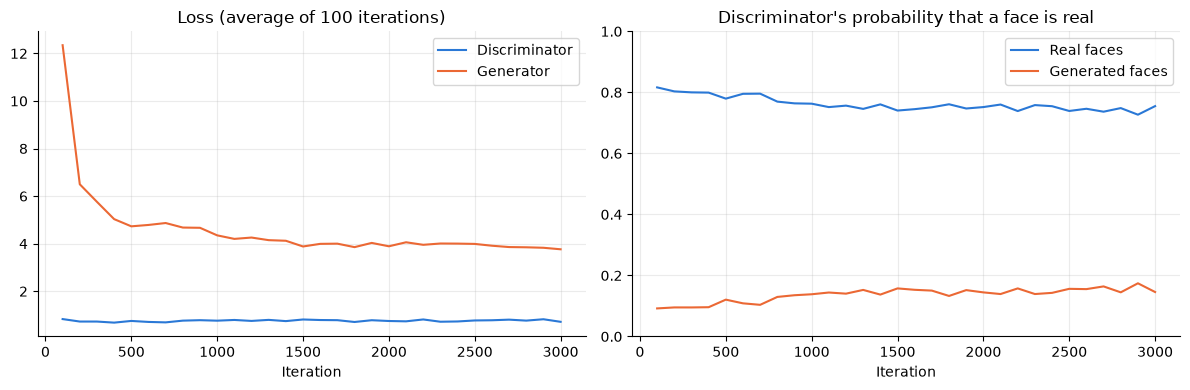

In [7]:
# Plot Training History
its = history['iteration']
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(its, history['loss_d'], color=COLORS[0], linewidth=1.5, label='Discriminator')
plt.plot(its, history['loss_g'], color=COLORS[1], linewidth=1.5, label='Generator')
plt.title('Loss (average of 100 iterations)')
plt.xlabel('Iteration')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(its, history['d_real'], color=COLORS[0], linewidth=1.5, label='Real faces')
plt.plot(its, history['d_fake'], color=COLORS[1], linewidth=1.5, label='Generated faces')
plt.ylim(0, 1)
plt.title("Discriminator's probability that a face is real")
plt.xlabel('Iteration')
plt.legend()
plt.tight_layout()
plt.savefig('gan_training_curves.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. Generated faces

All faces below come from the EMA generator. None of them is a real person: each is drawn from a new random vector $z$.

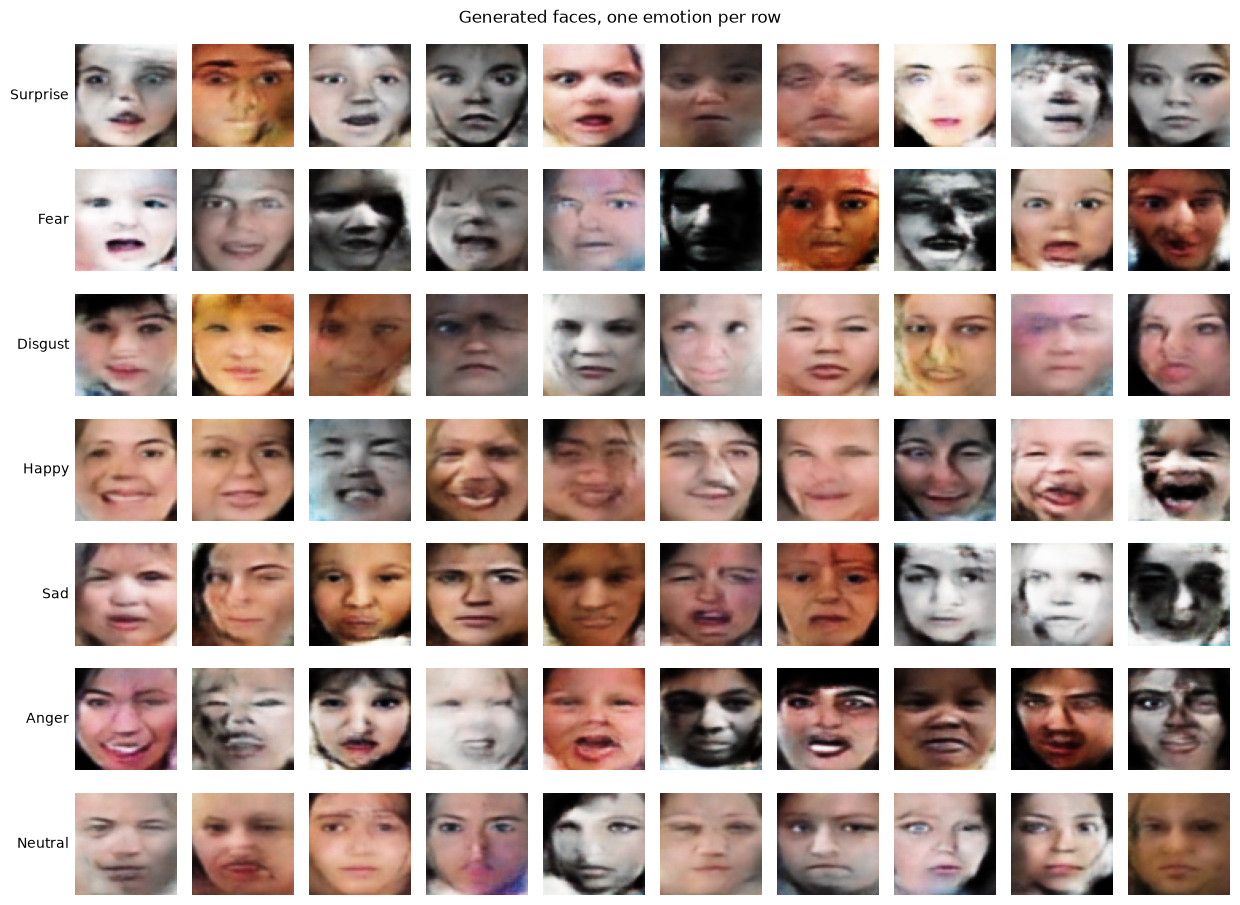

In [8]:
@torch.no_grad()
def generate(labels, z=None, seed=0):
    # Faces in [0, 1] for class indices (or class mixes as float vectors); z defaults to a seeded random draw
    labels = torch.as_tensor(labels, device=device)
    if z is None:
        z = torch.randn(len(labels), z_dim, generator=torch.Generator().manual_seed(seed)).to(device)
    out = [G_ema(z[i:i + 500], labels[i:i + 500]) for i in range(0, len(labels), 500)]
    return (torch.cat(out) * 0.5 + 0.5).clamp(0, 1)

def show_rows(images, ncol, row_names, title, path, scale=1.25, col_names=None):
    # Grid of faces with one label per row (and optionally per column)
    nrow = len(images) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * scale, nrow * scale + 0.5), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i].permute(1, 2, 0).cpu().numpy())
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if i % ncol == 0:
            ax.set_ylabel(row_names[i // ncol], fontsize=10, rotation=0, ha='right', va='center')
        if col_names and i < ncol:
            ax.set_title(col_names[i], fontsize=10)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches='tight')
    plt.show()

# Ten new faces for every emotion
per_row = 10
samples = generate(torch.arange(num_classes).repeat_interleave(per_row), seed=1)
show_rows(samples, per_row, emotion_names, 'Generated faces, one emotion per row', 'gan_samples.png')

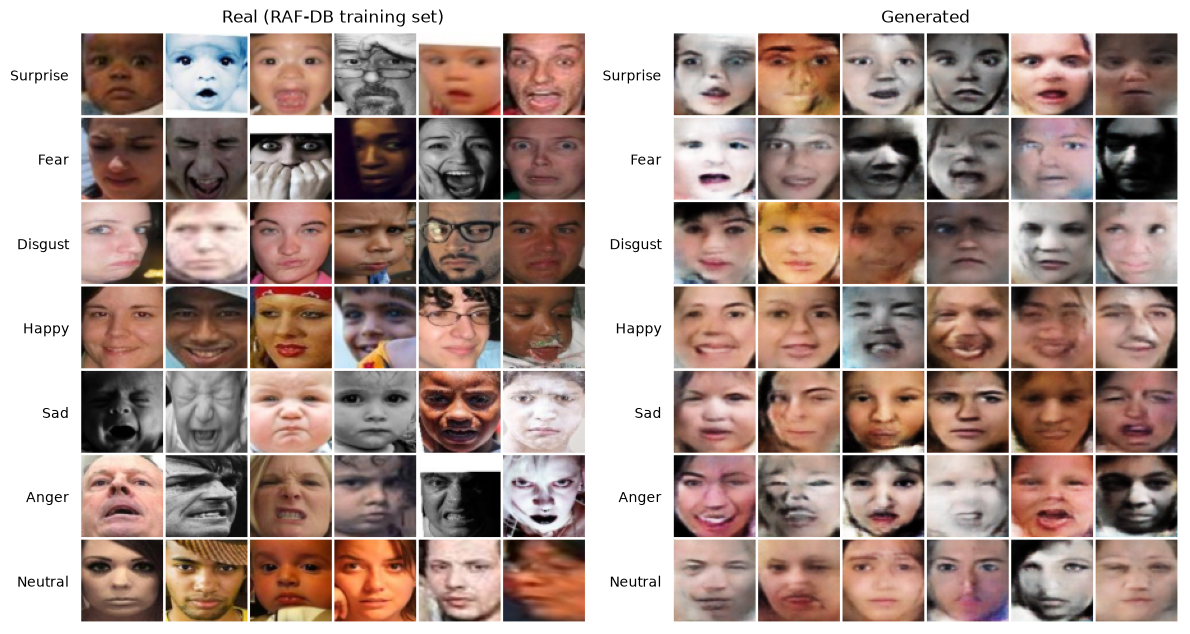

In [9]:
# Real RAF-DB training faces (left) next to generated faces (right), six of each per emotion
real_rows, fake_rows = [], []
gen = torch.Generator().manual_seed(3)
for c in range(num_classes):
    idx = torch.nonzero(train_labels == c).squeeze(1)
    pick = idx[torch.randperm(len(idx), generator=gen)[:6]]
    real_rows.append(train_images[pick])
    fake_rows.append(samples[c * per_row:c * per_row + 6].cpu())

fig, axes = plt.subplots(1, 2, figsize=(12, 7.6))
for ax, rows, name in zip(axes, [real_rows, fake_rows], ['Real (RAF-DB training set)', 'Generated']):
    ax.imshow(make_grid(torch.cat(rows), nrow=6, padding=2, pad_value=1).permute(1, 2, 0).numpy())
    ax.set_yticks([image_size / 2 + 2 + r * (image_size + 2) for r in range(num_classes)], emotion_names)
    ax.set_xticks([])
    ax.tick_params(left=False)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig('gan_real_vs_generated.png', dpi=200, bbox_inches='tight')
plt.show()

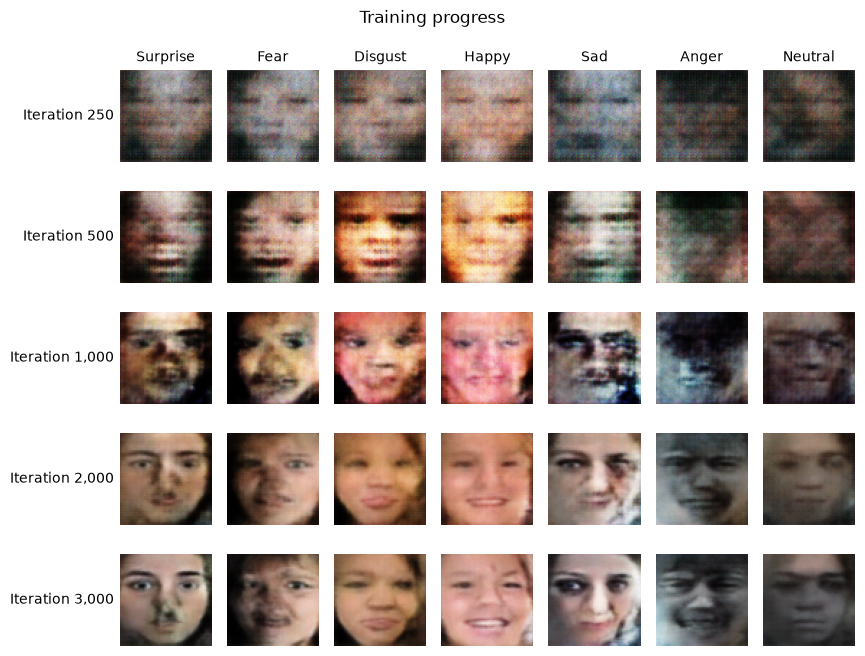

In [10]:
# The same seven fixed inputs at several points during training (EMA generator from iteration 1,000 on)
iters = sorted(snapshots)
progress = torch.cat([snapshots[i] for i in iters])
show_rows(progress, num_classes, [f'Iteration {i:,}' for i in iters], 'Training progress', 'gan_progress.png',
          col_names=emotion_names)

### One identity, seven emotions

Because the emotion only enters through the BatchNorm scales and shifts, keeping $z$ fixed and changing $y$ keeps most of the face (pose, skin tone, hair, background) and changes the expression. Each row below is one random $z$ rendered with all seven labels.

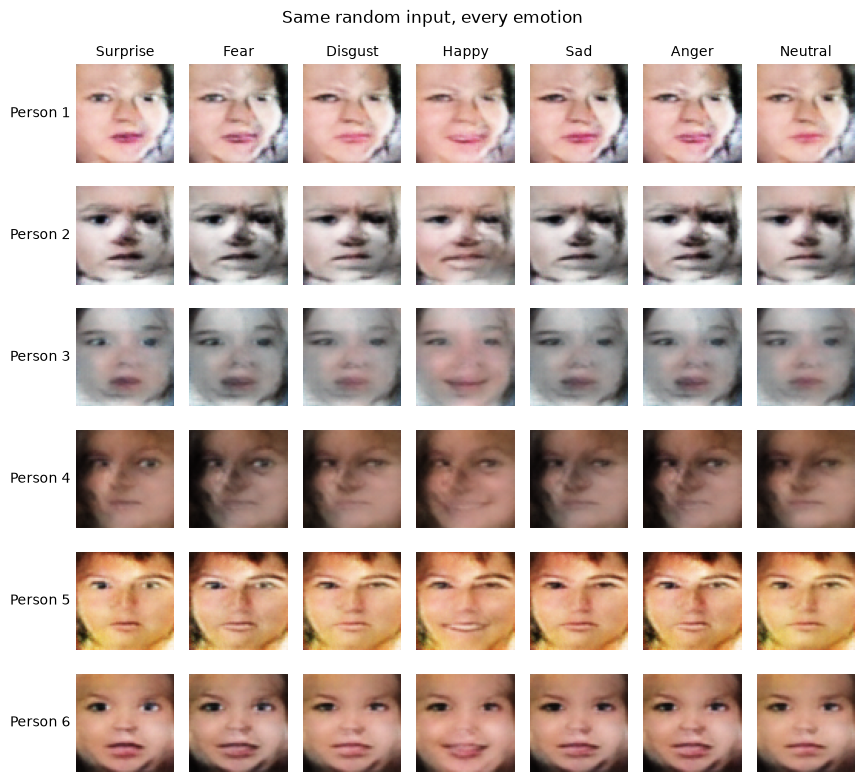

In [11]:
identities = 6
z = torch.randn(identities, z_dim, generator=torch.Generator().manual_seed(11)).to(device)
grid = generate(torch.arange(num_classes).repeat(identities), z=z.repeat_interleave(num_classes, dim=0))
show_rows(grid, num_classes, [f'Person {i + 1}' for i in range(identities)], 'Same random input, every emotion',
          'gan_emotion_transfer.png', col_names=emotion_names)

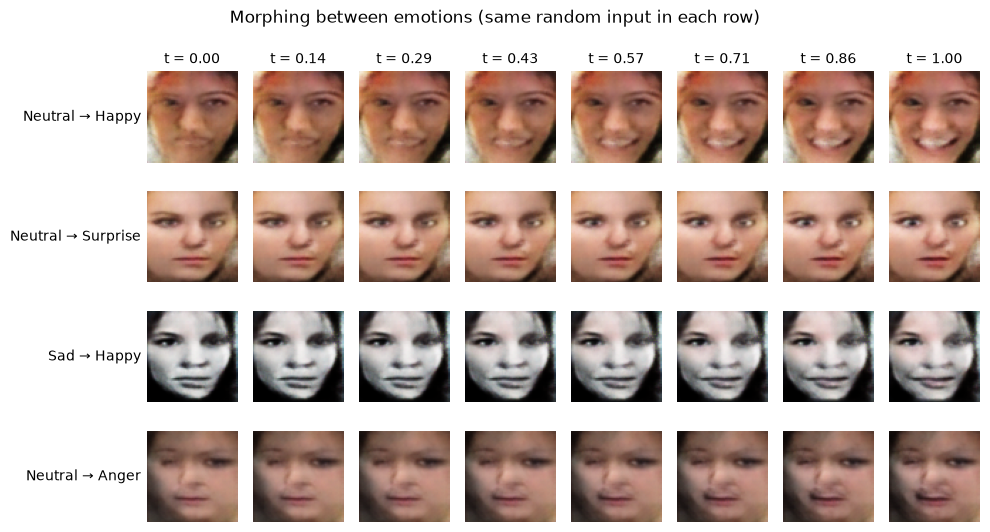

In [12]:
# Morph between two emotions by mixing their conditional-BatchNorm parameters: y = (1 - t) * e_a + t * e_b
steps = 8
pairs = [(6, 3), (6, 0), (4, 3), (6, 5)]  # Neutral -> Happy, Neutral -> Surprise, Sad -> Happy, Neutral -> Anger
z = torch.randn(len(pairs), z_dim, generator=torch.Generator().manual_seed(5)).to(device)
t = torch.linspace(0, 1, steps)
mixes = []
for a, b in pairs:
    mix = torch.zeros(steps, num_classes)
    mix[:, a], mix[:, b] = 1 - t, t
    mixes.append(mix)
morphs = generate(torch.cat(mixes), z=z.repeat_interleave(steps, dim=0))
show_rows(morphs, steps, [f'{emotion_names[a]} → {emotion_names[b]}' for a, b in pairs],
          'Morphing between emotions (same random input in each row)', 'gan_interpolation.png',
          col_names=[f't = {v:.2f}' for v in t.tolist()])

## 4. Do the faces show the requested emotion?

A conditional GAN can make realistic faces that ignore their label. To check the label, each of the three RAF-DB classifiers from `Video Predicition/` (87–88% test accuracy) classifies 500 generated faces per emotion, and we count how often it recognises the emotion the generator was asked for.

The generated faces are 64×64, smaller than the 100×100 images the classifiers were trained on, and the lower resolution alone costs some accuracy. For a fair reference, the classifiers are also run on the **real RAF-DB test faces downscaled to 64×64**. All images get the classifiers' test preprocessing (resize to 224×224, ImageNet normalization).

In [13]:
def load_classifier(name):
    # Rebuild a RAF-DB classifier with its Dropout + Linear head and load its trained weights
    if name == 'ResNet-18':
        model = models.resnet18()
        model.fc = nn.Sequential(nn.Dropout(p=0.5), nn.Linear(model.fc.in_features, 7))
        weights = 'resnet18_rafdb_final.pth'
    elif name == 'DenseNet-121':
        model = models.densenet121()
        model.classifier = nn.Sequential(nn.Dropout(p=0.5), nn.Linear(model.classifier.in_features, 7))
        weights = 'densenet121_rafdb_final.pth'
    else:
        model = models.efficientnet_b0()
        model.classifier = nn.Sequential(nn.Dropout(p=0.5), nn.Linear(model.classifier[1].in_features, 7))
        weights = 'efficientnet_b0_rafdb_final.pth'
    model.load_state_dict(torch.load(f'../Video Predicition/{weights}', map_location=device))
    return model.to(device).eval()

classifiers = {name: load_classifier(name) for name in ['ResNet-18', 'DenseNet-121', 'EfficientNet-B0']}

imagenet_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
imagenet_std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def classifier_input(images):
    # The classifiers' test preprocessing: resize to 224x224, then ImageNet normalization
    images = F.interpolate(images.to(device), size=(224, 224), mode='bilinear', align_corners=False)
    return (images - imagenet_mean) / imagenet_std

@torch.no_grad()
def predict(model, images, batch=100):
    return torch.cat([model(classifier_input(images[i:i + batch])).argmax(1).cpu() for i in range(0, len(images), batch)])

def per_class_accuracy(preds, labels):
    return [(preds[labels == c] == c).float().mean().item() for c in range(num_classes)]

per_class = 500
gen_labels = torch.arange(num_classes).repeat_interleave(per_class)
generated = generate(gen_labels, seed=2024).cpu()

agreement = {}
for name, model in classifiers.items():
    agreement[name] = {
        'real_64px': per_class_accuracy(predict(model, test_images), test_labels),
        'generated': per_class_accuracy(predict(model, generated), gen_labels),
    }

print(f"Share of faces classified as the intended emotion ({per_class} generated faces per emotion; "
      f"real = {len(test_images)} RAF-DB test faces at 64x64)\n")
print(f"{'':<28}" + ''.join(f'{e:>10}' for e in emotion_names) + f"{'Mean':>10}")
for name, acc in agreement.items():
    for kind, label in [('real_64px', 'real'), ('generated', 'generated')]:
        row = acc[kind]
        print(f"{name + ', ' + label:<28}" + ''.join(f'{v:>10.1%}' for v in row) + f"{np.mean(row):>10.1%}")

Share of faces classified as the intended emotion (500 generated faces per emotion; real = 3068 RAF-DB test faces at 64x64)

                              Surprise      Fear   Disgust     Happy       Sad     Anger   Neutral      Mean
ResNet-18, real                  87.2%     52.7%     59.4%     94.2%     79.1%     76.5%     88.4%     76.8%
ResNet-18, generated             76.0%      7.0%     17.8%     97.6%     26.4%      7.0%     76.6%     44.1%
DenseNet-121, real               86.9%     60.8%     55.6%     94.6%     78.5%     82.7%     88.8%     78.3%
DenseNet-121, generated          72.6%      4.8%     13.0%     98.0%     24.6%     11.0%     75.2%     42.7%
EfficientNet-B0, real            88.8%     51.4%     65.6%     93.8%     82.4%     79.6%     85.3%     78.1%
EfficientNet-B0, generated       72.6%      5.4%     19.4%     96.6%     26.4%     11.2%     72.4%     43.4%


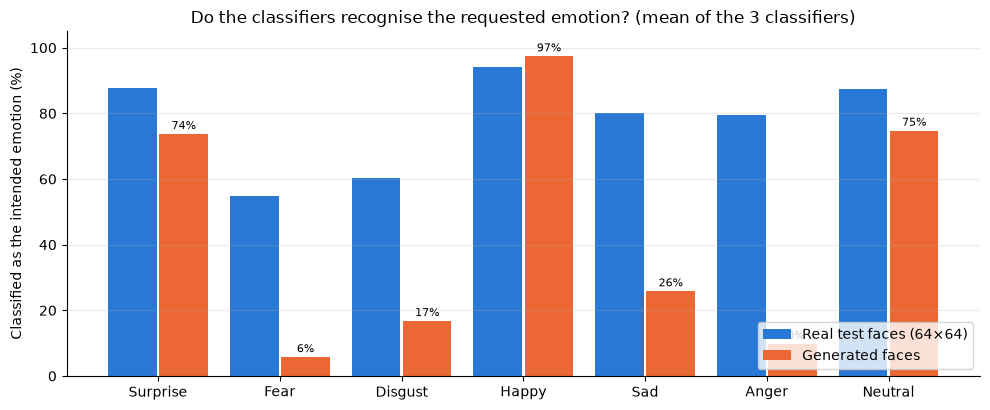

In [14]:
# Per-emotion agreement, averaged over the three classifiers
real_mean = np.mean([agreement[n]['real_64px'] for n in classifiers], axis=0)
gen_mean = np.mean([agreement[n]['generated'] for n in classifiers], axis=0)
x = np.arange(num_classes)
plt.figure(figsize=(10, 4.2))
plt.bar(x - 0.21, real_mean * 100, width=0.4, color=COLORS[0], label='Real test faces (64×64)')
plt.bar(x + 0.21, gen_mean * 100, width=0.4, color=COLORS[1], label='Generated faces')
for xi, v in zip(x, gen_mean):
    plt.text(xi + 0.21, v * 100 + 1.5, f'{v:.0%}', ha='center', fontsize=8)
plt.xticks(x, emotion_names)
plt.ylim(0, 105)
plt.ylabel('Classified as the intended emotion (%)')
plt.title('Do the classifiers recognise the requested emotion? (mean of the 3 classifiers)')
plt.legend(loc='lower right')
plt.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig('gan_classifier_check.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. Realism, diversity and memorisation

**Fréchet distance.** The Fréchet Inception Distance (FID, Heusel et al., 2017) compares the mean and covariance of image features from real and generated sets; lower is better. Instead of an ImageNet Inception network, the features here are the 1,280-dimensional penultimate layer of the RAF-DB EfficientNet-B0 classifier, so the distance measures differences that matter for faces and expressions. The values are therefore **not comparable with FID numbers in papers**; the reference point is the distance between two sets of *real* faces of the same size (training versus test), which shows the floor a perfect generator would reach.

All sets have 3,068 images at 64×64. The generated set uses the labels of the test set, so the class balance matches.

In [15]:
@torch.no_grad()
def features(images, batch=100):
    # EfficientNet-B0 penultimate features (after global average pooling)
    model = classifiers['EfficientNet-B0']
    return torch.cat([model.avgpool(model.features(classifier_input(images[i:i + batch]))).flatten(1).cpu()
                      for i in range(0, len(images), batch)]).double().numpy()

def frechet_distance(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    # tr(sqrt(s1 s2)) = tr(sqrt(sqrt(s1) s2 sqrt(s1))), which only needs symmetric eigendecompositions
    w, v = np.linalg.eigh(s1)
    sqrt_s1 = (v * np.sqrt(w.clip(0))) @ v.T
    tr_covmean = np.sqrt(np.linalg.eigvalsh(sqrt_s1 @ s2 @ sqrt_s1).clip(0)).sum()
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr_covmean)

n = len(test_images)
test_features = features(test_images)
train_subset = torch.randperm(len(train_images), generator=torch.Generator().manual_seed(0))[:n]
G_raw = G.eval()  # the last training weights, without EMA, for comparison
with torch.no_grad():
    z = torch.randn(n, z_dim, generator=torch.Generator().manual_seed(99)).to(device)
    raw = torch.cat([G_raw(z[i:i + 500], test_labels[i:i + 500].to(device)) for i in range(0, n, 500)]) * 0.5 + 0.5

fd = {
    'real_train_vs_test': frechet_distance(features(train_images[train_subset]), test_features),
    'generated_ema_vs_test': frechet_distance(features(generate(test_labels, z=z)), test_features),
    'generated_raw_vs_test': frechet_distance(features(raw.clamp(0, 1)), test_features),
}
print(f"Fréchet distance in EfficientNet-B0 feature space ({n} images per set, lower is better)")
print(f"  Real training faces vs real test faces (floor): {fd['real_train_vs_test']:7.1f}")
print(f"  Generated faces (EMA generator) vs test faces:   {fd['generated_ema_vs_test']:7.1f}")
print(f"  Generated faces (last weights, no EMA) vs test:  {fd['generated_raw_vs_test']:7.1f}")

Fréchet distance in EfficientNet-B0 feature space (3068 images per set, lower is better)
  Real training faces vs real test faces (floor):     2.7
  Generated faces (EMA generator) vs test faces:       9.1
  Generated faces (last weights, no EMA) vs test:     12.7


**Memorisation check.** A GAN trained on a small dataset can end up reproducing its training images. For one generated face per emotion, the three closest RAF-DB training faces (smallest pixel distance at 64×64, over all 12,271 images) are shown next to it. If the GAN copied the training data, the nearest neighbour would be the same face.

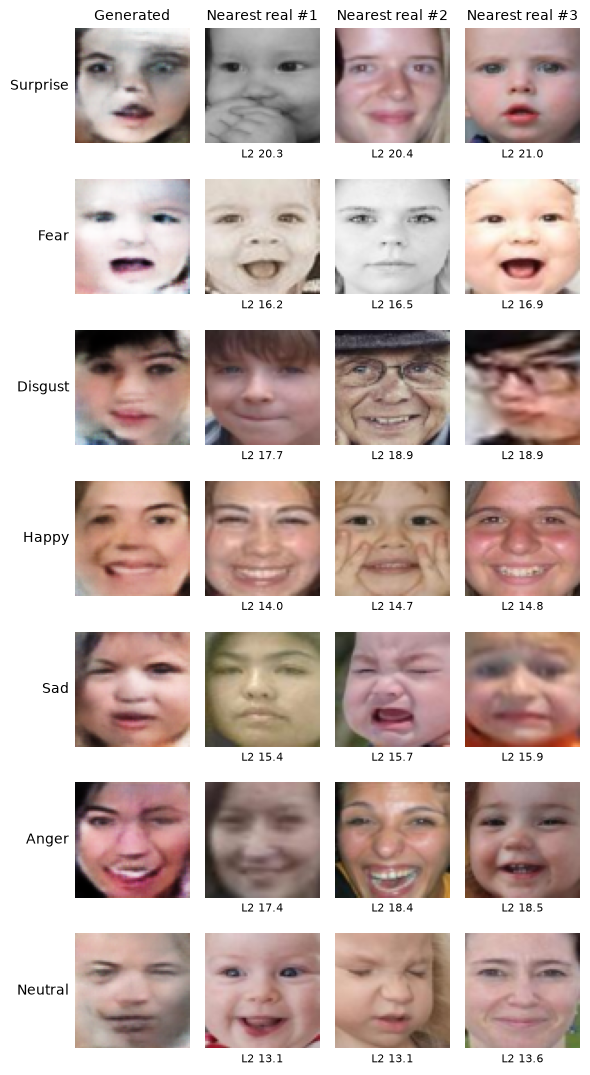

In [16]:
queries = samples[torch.arange(num_classes) * per_row]  # the first face of each row of the sample grid
train_flat = train_images.flatten(1).to(device)
dist = torch.cdist(queries.flatten(1), train_flat)  # L2 distance to every training face
nearest = dist.topk(3, largest=False)

cols = 4
fig, axes = plt.subplots(num_classes, cols, figsize=(cols * 1.5, num_classes * 1.5 + 0.4))
for r in range(num_classes):
    row = [queries[r]] + [train_images[i] for i in nearest.indices[r].tolist()]
    for c in range(cols):
        ax = axes[r, c]
        ax.imshow(row[c].permute(1, 2, 0).cpu().numpy())
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if c == 0:
            ax.set_ylabel(emotion_names[r], rotation=0, ha='right', va='center')
        else:
            ax.set_xlabel(f'L2 {nearest.values[r, c - 1]:.1f}', fontsize=8)
axes[0, 0].set_title('Generated', fontsize=10)
for c in range(1, cols):
    axes[0, c].set_title(f'Nearest real #{c}', fontsize=10)
plt.tight_layout()
plt.savefig('gan_nearest_neighbours.png', dpi=200, bbox_inches='tight')
plt.show()

In [17]:
# Save all numbers for the README, the web UI and the report
results = {
    'dataset': 'RAF-DB',
    'image_size': image_size,
    'train_images': len(train_images),
    'model': {
        'type': 'conditional DCGAN: generator with conditional BatchNorm, projection discriminator, non-saturating loss',
        'z_dim': z_dim,
        'generator_parameters': sum(p.numel() for p in G_ema.parameters()),
        'discriminator_parameters': sum(p.numel() for p in D.parameters()),
        'real_label_smoothing': real_target,
    },
    'training': {
        'iterations': num_iters, 'batch_size': batch_size, 'lr': lr, 'betas': list(betas),
        'ema_decay': ema_decay, 'ema_start': ema_start, 'minutes': round(training_minutes, 1), 'device': str(device),
    },
    'history': history,
    'classifier_agreement': {'per_class_generated': per_class, 'emotions': emotion_names, 'models': agreement},
    'frechet_distance': {'features': 'EfficientNet-B0 (RAF-DB) penultimate layer, 1280-d', 'images_per_set': n, **fd},
}
with open('results.json', 'w') as f:
    json.dump(results, f, indent=2)
print("✅ Results saved to 'results.json'")

✅ Results saved to 'results.json'
